# 02 · Log parsing with Drain
Each line is split into a fixed template and variable parameters. Masks for block IDs, IPs, hex values and numbers run before Drain.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PARSED_DIR, RAW_DIR, RESULTS_DIR, SEQUENCES_DIR

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#888",
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_colwidth", 120)

In [2]:
from src.parsing.drain import LogParser
parser = LogParser()
lines = ["Received block blk_38865049064139660 of size 67108864 from /10.251.42.84",
         "Received block blk_-6952295868487656571 of size 3542 from /10.251.90.64",
         "PacketResponder 1 for block blk_38865049064139660 terminating",
         "Deleting block blk_-1608999687919862906 file /mnt/hadoop/dfs/data/current/subdir24/blk_-1608999687919862906"]
ids = [parser.parse(l) for l in lines]
pd.DataFrame({"line": lines, "event_id": ids, "template": [parser.templates()[i][0] for i in ids]})

,line,event_id,template
0,Received block blk_38865049064139660 of size 67108864 from /10.251.42.84,1,Received block <BLK> of size <NUM> from /<IP>
1,Received block blk_-6952295868487656571 of size 3542 from /10.251.90.64,1,Received block <BLK> of size <NUM> from /<IP>
2,PacketResponder 1 for block blk_38865049064139660 terminating,2,PacketResponder <NUM> for block <BLK> terminating
3,Deleting block blk_-1608999687919862906 file /mnt/hadoop/dfs/data/current/subdir24/blk_-1608999687919862906,3,Deleting block <BLK> file /mnt/hadoop/dfs/data/current/subdir24/<BLK>


## Parsing accuracy
Grouping accuracy against Loghub's hand-labelled 2k-line samples, across Drain similarity thresholds.

In [3]:
from src.evaluation.parsing_accuracy import grouping_accuracy
rows = []
for ds in ("hdfs", "bgl"):
    gt = pd.read_csv(RAW_DIR / ds / f"{ds.upper()}_2k.log_structured.csv")
    for th in (0.3, 0.4, 0.5, 0.6, 0.7):
        p = LogParser(sim_th=th)
        pred = np.array([p.parse(str(c)) for c in gt.Content])
        rows.append({"dataset": ds.upper(), "sim_th": th, "templates": len(set(pred)),
                     "true templates": gt.EventId.nunique(), "accuracy": grouping_accuracy(gt.EventId.to_numpy(), pred)})
acc = pd.DataFrame(rows)
acc.pivot(index="sim_th", columns="dataset", values="accuracy").round(3)

dataset,BGL,HDFS
sim_th,,
0.3,0.931,0.998
0.4,0.968,0.998
0.5,0.968,0.998
0.6,0.876,0.998
0.7,0.880,0.998


`sim_th = 0.4` (the default used everywhere) is at or near the best for both datasets.

## Templates found in the full logs

In [4]:
for ds in ("hdfs", "bgl"):
    t = pd.read_csv(PARSED_DIR / f"{ds}_templates.csv").sort_values("count", ascending=False)
    print(f"{ds.upper()}: {len(t)} templates; top 10 cover {t['count'].head(10).sum() / t['count'].sum():.1%} of lines")
    display(t.head(8))

HDFS: 45 templates; top 10 cover 99.6% of lines


,event_id,template,count
0,1,Receiving block <BLK> src: /<IP> dest: /<IP>,1723232
4,5,BLOCK* NameSystem.addStoredBlock: blockMap updated: <IP> is added to <BLK> size <NUM>,1719741
2,3,PacketResponder <NUM> for block <BLK> <*>,1706728
3,4,Received block <BLK> of size <NUM> from /<IP>,1706514
16,17,Deleting block <BLK> file <*>,1402047
31,32,BLOCK* NameSystem.delete: <BLK> is added to invalidSet of <IP>,1396174
1,2,BLOCK* NameSystem.allocateBlock: <*> <BLK>,575061
9,10,<IP> Served block <BLK> to /<IP>,428726


BGL: 1124 templates; top 10 cover 74.3% of lines


,event_id,template,count
2,3,generating core.<NUM>,1706751
409,410,iar <*> dear <*>,442966
10,11,<NUM> double-hummer alignment exceptions,295764
218,219,<NUM> floating point alignment exceptions,267725
5,6,"CE sym <NUM>, at <HEX>, mask <HEX>",201206
17,18,data TLB error interrupt,152734
938,939,<NUM> microseconds spent in the rbs signal handler during <NUM> calls. <NUM> microseconds was the maximum time for a...,135092
939,940,<NUM> total interrupts. <NUM> critical input interrupts. <NUM> microseconds total spent on critical input interrupts...,135092


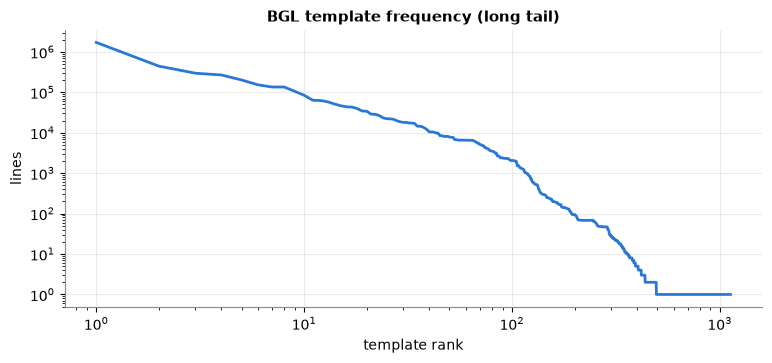

In [5]:
t = pd.read_csv(PARSED_DIR / "bgl_templates.csv").sort_values("count", ascending=False)
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(t) + 1), t["count"].to_numpy(), color=BLUE, lw=2)
ax.set(xscale="log", yscale="log", title="BGL template frequency (long tail)", xlabel="template rank", ylabel="lines"); plt.show()